In [274]:
### Load necessary modules -------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import csv
import sys

# Machine learning libraries
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    recall_score, precision_score, f1_score, cohen_kappa_score,
    roc_curve, auc, RocCurveDisplay
)
from sklearn.calibration import CalibrationDisplay
from sklearn.impute import SimpleImputer

# Configuration for plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10, 6]

# Ignore warnings
import warnings
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)


In [ ]:


repo_root = Path.cwd().resolve()
while not (repo_root / "course_files").is_dir():
    if repo_root == repo_root.parent:
        raise FileNotFoundError("Impossible de trouver course_files/")
    repo_root = repo_root.parent

sys.path.insert(0, str(repo_root))
from course_files.helpers import load_csv_data


data_dir = repo_root / "data"
if not data_dir.is_dir():
    raise FileNotFoundError(f"Dossier data introuvable : {data_dir}")

XTR = pd.read_csv(data_dir / "x_train.csv")
YTR = pd.read_csv(data_dir / "y_train.csv")
XTS  = pd.read_csv(data_dir / "x_test.csv")

df_raw = pd.concat([XTR, YTR], axis=1)

In [276]:
df_raw.head()

,Id,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,...,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3,Id,_MICHD
0,0,53,11,11162015,11,16,2015,1100,2015015629,2015015629,...,3.0,3.0,4.0,1,1,NaN,NaN,2.0,0,-1
1,1,33,12,12152015,12,15,2015,1200,2015004387,2015004387,...,3.0,3.0,4.0,9,9,NaN,NaN,NaN,1,-1
2,2,20,10,10202015,10,20,2015,1100,2015005638,2015005638,...,2.0,2.0,3.0,1,1,1.0,2.0,2.0,2,-1
3,3,42,6,6182015,6,18,2015,1100,2015004694,2015004694,...,2.0,2.0,3.0,1,1,2.0,2.0,2.0,3,-1
4,4,24,11,11062015,11,6,2015,1100,2015004673,2015004673,...,3.0,3.0,4.0,1,1,9.0,9.0,2.0,4,-1


In [277]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 328135 entries, 0 to 328134
Columns: 324 entries, Id to _MICHD
dtypes: float64(244), int64(80)
memory usage: 811.1 MB


In [280]:
relevant_cols = {
    '_AGEG5YR': 'Age_Group',
    'SEX' : 'Sex',
    'GENHLTH': 'General_Health',
    '_BMI5'  : 'BMI',
    'PHYSHLTH': 'Physical_Health_DaysPoor',
    '_TOTINDA': 'Any activity',
    'DIABETE3': 'Diabetes',
    'CVDSTRK3' : 'Strokes',
    'BPHIGH4' : 'Hypertension',
    '_RFCHOL' : 'High Colesterole', 
    '_SMOKER3' : 'Smoking',
    '_INCOMG' : 'Income',
    '_MICHD': 'Heart Failure'
}

df = df_raw[list(relevant_cols.keys())].rename(columns=relevant_cols)
df.head()

,Age_Group,Sex,General_Health,BMI,Physical_Health_DaysPoor,Any activity,Diabetes,Strokes,Hypertension,High Colesterole,Smoking,Income,Heart Failure
0,8,2,2.0,20.78,1.0,1,3.0,2,3.0,1.0,1,5,-1
1,8,1,4.0,28.70,88.0,9,3.0,2,1.0,1.0,1,5,-1
2,10,2,2.0,NaN,77.0,1,3.0,2,3.0,2.0,3,9,-1
3,10,2,1.0,27.96,88.0,1,3.0,2,3.0,1.0,1,9,-1
4,14,1,2.0,24.39,88.0,1,3.0,2,3.0,1.0,9,9,-1


In [281]:
""" # Convert special codes to NaN (coded as 7, 9, 77, 99, etc.)
na_values = [7, 9, 77, 99]
df.replace(na_values, pd.NA, inplace=True)

# Drop rows with any NA in the selected columns
df_clean = df.dropna().copy()
print(f'Clean rows: {df_clean.shape[0]:,}  |  Columns: {df_clean.shape[1]}') """



" # Convert special codes to NaN (coded as 7, 9, 77, 99, etc.)\nna_values = [7, 9, 77, 99]\ndf.replace(na_values, pd.NA, inplace=True)\n\n# Drop rows with any NA in the selected columns\ndf_clean = df.dropna().copy()\nprint(f'Clean rows: {df_clean.shape[0]:,}  |  Columns: {df_clean.shape[1]}') "

In [282]:

df_clean = df.copy() 

df_clean['Physical_Health_DaysPoor'] = df_clean['Physical_Health_DaysPoor'].replace({88: 0, 77: np.nan, 99: np.nan})
df_clean['BMI'] = df_clean['BMI'].where(df['BMI'] < 9999, np.nan)

#risk of 7 and 9 meaning missing 
cols_7_9_missing = [
    'Diabetes', 'Strokes', 'Hypertension', 'High Colesterole',
    'Smoking', 'Income', 'Any activity'  # these two are usually clean, but safe
]

for c in cols_7_9_missing:
    df_clean[c] = df_clean[c].replace({7: np.nan, 9: np.nan, 77: np.nan, 99: np.nan})

In [283]:
df_clean.head()

,Age_Group,Sex,General_Health,BMI,Physical_Health_DaysPoor,Any activity,Diabetes,Strokes,Hypertension,High Colesterole,Smoking,Income,Heart Failure
0,8,2,2.0,20.78,1.0,1.0,3.0,2.0,3.0,1.0,1.0,5.0,-1
1,8,1,4.0,28.70,0.0,NaN,3.0,2.0,1.0,1.0,1.0,5.0,-1
2,10,2,2.0,NaN,NaN,1.0,3.0,2.0,3.0,2.0,3.0,NaN,-1
3,10,2,1.0,27.96,0.0,1.0,3.0,2.0,3.0,1.0,1.0,NaN,-1
4,14,1,2.0,24.39,0.0,1.0,3.0,2.0,3.0,1.0,NaN,NaN,-1


In [284]:
# Cast categorical fields
cat_inputs = ['Sex', 'Any activity', 'Strokes', 'Diabetes', 'Hypertension', 'High Colesterole', 'Smoking']
output = ['Heart Failure']
num_inputs = ['Age_Group', 'General_Health', 'BMI', 'Physical_Health_DaysPoor']

for col in cat_inputs:
    df_clean[col] = df_clean[col].astype('category')


#Manual OHE 
""" ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
ohe_result = ohe.fit_transform(df_clean[cat_inputs])
ohe_inputs = ohe.get_feature_names_out(cat_inputs).tolist()
ohe_df = pd.DataFrame(ohe_result, columns=ohe_inputs)
df_clean = pd.concat([df_clean.drop(columns=cat_inputs), ohe_df], axis=1) """
#df_clean[num_inputs] = df_clean[num_inputs].astype('float64')

# BMI is stored as BMI*100 → convert to true BMI
#df_clean['BMI'] = df_clean['BMI'] / 100

" ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')\nohe_result = ohe.fit_transform(df_clean[cat_inputs])\nohe_inputs = ohe.get_feature_names_out(cat_inputs).tolist()\nohe_df = pd.DataFrame(ohe_result, columns=ohe_inputs)\ndf_clean = pd.concat([df_clean.drop(columns=cat_inputs), ohe_df], axis=1) "

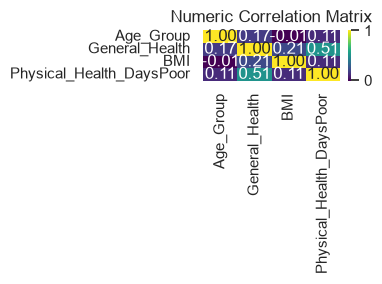

In [296]:
# Correlation matrix for numeric vars
corr = df_clean[num_inputs].corr()

plt.figure(figsize=(4,3))
sns.heatmap(corr, annot=True, cmap='viridis', fmt='.2f')
plt.title('Numeric Correlation Matrix')
plt.tight_layout()
plt.show()

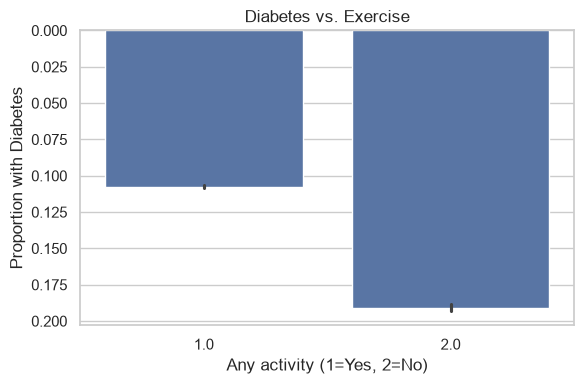

In [297]:
# Heart Failure prevalence by exercise status
plt.figure(figsize=(6,4))
sns.barplot(x='Any activity', y='Diabetes', data=df_clean, estimator=lambda x: (x==1).mean())
plt.ylabel('Proportion with Diabetes')
plt.xlabel('Any activity (1=Yes, 2=No)')
plt.title('Diabetes vs. Exercise')
plt.tight_layout()
plt.show()

In [301]:
# Age buckets (already coded 1–13 for five‑year bands)
age_map = {
    1:'18–24',2:'25–29',3:'30–34',4:'35–39',5:'40–44',6:'45–49',7:'50–54',
    8:'55–59',9:'60–64',10:'65–69',11:'70–74',12:'75–79',13:'80+'}
df_clean['Age_Bucket'] = df_clean['Age_Group'].map(age_map)

# BMI categories
bins = [0,18.5,25,30,100]
labels = ['Underweight','Healthy','Overweight','Obese']
df_clean['BMI_Class'] = pd.cut(df_clean['BMI'], bins=bins, labels=labels)


In [302]:
# Pivot table: Diabetes prevalence by BMI class and Exercise status
pivot = pd.pivot_table(
    df_clean,
    values='Diabetes',
    index='BMI_Class',
    columns='Any activity',
    aggfunc=lambda x: (x==1).mean()
)
pivot.columns = ['Exercised','No Exercise']
pivot.style.format('{:.1%}')

,Exercised,No Exercise
BMI_Class,,
Underweight,3.6%,6.6%
Healthy,4.8%,9.0%
Overweight,10.2%,15.7%
Obese,20.0%,29.2%


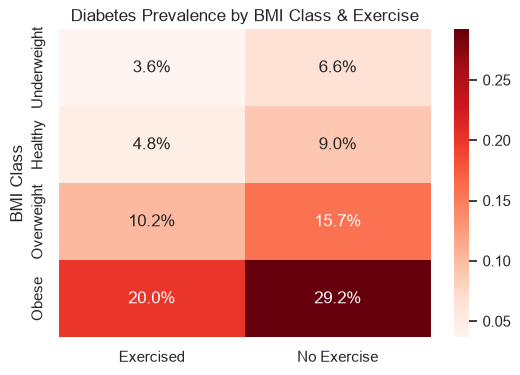

In [303]:
plt.figure(figsize=(6,4))
sns.heatmap(pivot, annot=True, fmt='.1%', cmap='Reds')
plt.title('Diabetes Prevalence by BMI Class & Exercise')
plt.ylabel('BMI Class')
plt.show()

In [285]:
XTR2 = df_clean.drop(columns=output)
YTR2 = df_clean[output]

In [286]:
preprocessor = ColumnTransformer([
    # Numériques : médiane, puis standardisation
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('scl', StandardScaler()),
    ]), num_inputs),

    # Catégorielles : "missing" explicite, puis OHE
    ('cat', Pipeline([
        ('imp', SimpleImputer(strategy='constant', fill_value=-1)),
        ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)),
    ]), cat_inputs),
])


""" #pipeline with preproc only 
Gen_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', C=1.0)),
])

_ = Gen_pipe.set_output(transform="pandas") """

' #pipeline with preproc only \nGen_pipe = Pipeline([\n    (\'prep\', preprocessor),\n    (\'clf\', LogisticRegression(max_iter=1000, class_weight=\'balanced\', C=1.0)),\n])\n\n_ = Gen_pipe.set_output(transform="pandas") '

In [287]:
preprocessor.fit(XTR2)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [288]:
YTR2.head()

,Heart Failure
0,-1
1,-1
2,-1
3,-1
4,-1


In [289]:
YTR3 = (YTR2 + 1) / 2
YTR3.head()

,Heart Failure
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0


In [290]:
XTR_pp = preprocessor.transform(XTR2)
#XTS_pp = preprocessor.transform(XTS2)

In [291]:
#Baseline SK model of Logistic reg 
from sklearn.linear_model import LogisticRegression as SkLogistic
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, roc_auc_score
from sklearn.metrics import make_scorer

sys.path.append(str(Path.cwd().parent))
y = YTR3.values.ravel()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)



In [292]:


from implementations_wrapper import (
    CustomLogisticRegression,
    CustomRegLogisticRegression,
    CustomSVM,
    CustomLinearRegression,
    CustomRidgeRegression,
)

def auc_scorer(estimator, X, y):
    if len(np.unique(y)) < 2:
        return np.nan
    if hasattr(estimator, 'decision_function'):
        s = estimator.decision_function(X)
    else:
        s = estimator.predict_proba(X)
        if s.ndim == 2:
            s = s[:, 1]
    return roc_auc_score(y, s)

classif_models = {
    'Custom LR':    Pipeline([('prep', preprocessor),
                              ('clf', CustomLogisticRegression(max_it=1000, gamma=0.1))]),
    'Custom RegLR': Pipeline([('prep', preprocessor),
                              ('clf', CustomRegLogisticRegression(lmbd=0.01, max_it=1000, gamma=0.1))]),
    'Custom SVM':   Pipeline([('prep', preprocessor),
                              ('clf', CustomSVM(lmbd=0.01, max_it=2000, gamma=0.1))]),
    'SK LR':        Pipeline([('prep', preprocessor),
                            ('clf', SkLogistic(max_iter=1000, class_weight='balanced', C=1.0))])
}

results_clf = {}
for name, pipe in classif_models.items():
    clf = pipe.named_steps['clf']
    method = 'decision_function' if hasattr(clf, 'decision_function') else 'predict_proba'
    scoring = make_scorer(auc_scorer, response_method=method)
    scores = cross_val_score(pipe, XTR2, y, cv=cv, scoring=auc_scorer,
                             n_jobs=-1, error_score='raise')
    results_clf[name] = (np.nanmean(scores), np.nanstd(scores))
    print(f"{name:15s}: AUC = {scores.mean():.4f} ± {scores.std():.4f}  folds={scores}")


Custom LR      : AUC = 0.8447 ± 0.0012  folds=[0.8451706  0.84384005 0.84506512 0.8463418  0.84287479]
Custom RegLR   : AUC = 0.8420 ± 0.0014  folds=[0.84239352 0.84141761 0.84181098 0.84437838 0.84004475]
Custom SVM     : AUC = 0.7934 ± 0.0651  folds=[0.6646976  0.8369481  0.8364953  0.8163459  0.81231758]
SK LR          : AUC = 0.8478 ± 0.0010  folds=[0.84869914 0.84780778 0.84802412 0.84841821 0.84594827]


In [293]:
XTR2.head()

,Age_Group,Sex,General_Health,BMI,Physical_Health_DaysPoor,Any activity,Diabetes,Strokes,Hypertension,High Colesterole,Smoking,Income
0,8,2,2.0,20.78,1.0,1.0,3.0,2.0,3.0,1.0,1.0,5.0
1,8,1,4.0,28.70,0.0,NaN,3.0,2.0,1.0,1.0,1.0,5.0
2,10,2,2.0,NaN,NaN,1.0,3.0,2.0,3.0,2.0,3.0,NaN
3,10,2,1.0,27.96,0.0,1.0,3.0,2.0,3.0,1.0,1.0,NaN
4,14,1,2.0,24.39,0.0,1.0,3.0,2.0,3.0,1.0,NaN,NaN


In [294]:
from sklearn.model_selection import KFold

cv_reg = KFold(n_splits=5, shuffle=True, random_state=0)

def regression_auc_scorer(regressor, X, y, cv=cv):
    """Cross-validate a regressor and compute AUC of its raw scores."""
    aucs = []
    for train_idx, test_idx in cv_reg.split(X):
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]
        regressor.fit(X_tr, y_tr.astype(float))       # ← float pour MSE
        scores = regressor.predict(X_te)              # ← scores continus
        aucs.append(roc_auc_score(y_te, scores))      # ← AUC sur scores
    return np.array(aucs)

reg_models = {
    'MSE-GD':    Pipeline([('prep', preprocessor),
                           ('reg', CustomLinearRegression(method='gd', max_it=2000, gamma=0.1))]),
    'MSE-SGD':   Pipeline([('prep', preprocessor),
                           ('reg', CustomLinearRegression(method='sgd', max_it=5000, gamma=0.01))]),
    'OLS':       Pipeline([('prep', preprocessor),
                           ('reg', CustomLinearRegression(method='closed_form'))]),
    'Ridge':     Pipeline([('prep', preprocessor),
                           ('reg', CustomRidgeRegression(lmbd=0.01))]),
}

results_reg = {}
for name, pipe in reg_models.items():
    try:
        aucs = regression_auc_scorer(pipe, XTR2, y, cv=cv)
        results_reg[name] = (aucs.mean(), aucs.std())
        print(f"{name:10s}: AUC = {aucs.mean():.4f} ± {aucs.std():.4f}")
    except Exception as e:
        print(f"{name:10s}: ERREUR — {type(e).__name__}: {e}")

MSE-GD    : AUC = 0.8411 ± 0.0030
MSE-SGD   : AUC = 0.8104 ± 0.0160
OLS       : AUC = 0.8412 ± 0.0031
Ridge     : AUC = 0.8419 ± 0.0030


In [295]:
print("\n" + "="*60)
print("sum up")
print("="*60)
print(f"{'Model':15s}  {'AUC':>8s}  {'Type':>10s}")
print("-"*40)
for name, (m, s) in results_clf.items():
    print(f"{name:15s}  {m:.4f}     classif")
for name, (m, s) in results_reg.items():
    print(f"{name:15s}  {m:.4f}     regression")

best = max({**results_clf, **results_reg}.items(), key=lambda x: x[1][0])
print(f"\nBest model : {best[0]} (AUC = {best[1][0]:.4f})")


sum up
Model                 AUC        Type
----------------------------------------
Custom LR        0.8447     classif
Custom RegLR     0.8420     classif
Custom SVM       0.7934     classif
SK LR            0.8478     classif
MSE-GD           0.8411     regression
MSE-SGD          0.8104     regression
OLS              0.8412     regression
Ridge            0.8419     regression

Best model : SK LR (AUC = 0.8478)


Remains the grid search